In [10]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    precision_recall_curve, average_precision_score
)

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_context('talk')

project_root = Path.cwd().resolve()
feature_path = None
for candidate in [project_root, project_root.parent]:
    p = candidate / 'data' / 'processed' / 'features.csv'
    if p.exists():
        feature_path = p
        break
if feature_path is None:
    raise FileNotFoundError('Could not find data/processed/features.csv in this workspace.')

df = pd.read_csv(feature_path)
print(f'Loaded data shape: {df.shape}')
print('\nColumns:')
print(df.columns.tolist())
print('\nTarget class counts:')
print(df['hallucinated'].value_counts().to_string())

df.head()

Loaded data shape: (17617, 18)

Columns:
['id', 'source_id', 'split', 'hallucinated', 'word_overlap', 'missing_numbers', 'missing_names', 'answer_length', 'length_ratio', 'task_type_Data2txt', 'task_type_QA', 'task_type_Summary', 'model_gpt-3.5-turbo-0613', 'model_gpt-4-0613', 'model_llama-2-13b-chat', 'model_llama-2-70b-chat', 'model_llama-2-7b-chat', 'model_mistral-7B-instruct']

Target class counts:
hallucinated
0    9976
1    7641


,id,source_id,split,hallucinated,word_overlap,missing_numbers,missing_names,answer_length,length_ratio,task_type_Data2txt,task_type_QA,task_type_Summary,model_gpt-3.5-turbo-0613,model_gpt-4-0613,model_llama-2-13b-chat,model_llama-2-70b-chat,model_llama-2-7b-chat,model_mistral-7B-instruct
0,0,15592,train,0,0.863636,0,2,110,0.235546,0,0,1,0,1,0,0,0,0
1,1,15592,train,0,0.812500,0,3,128,0.274090,0,0,1,1,0,0,0,0,0
2,2,15592,train,1,0.792453,1,1,159,0.340471,0,0,1,0,0,0,0,0,1
3,3,15592,train,1,0.760000,1,5,125,0.267666,0,0,1,0,0,0,0,1,0
4,4,15592,train,0,0.808989,0,1,89,0.190578,0,0,1,0,0,1,0,0,0


# T09 - Train and Evaluate Baseline Models

This notebook follows the supervised-learning workflow in *Artificial Intelligence: Foundations of Computational Agents*. The objective of this task is to train a small set of baseline classifiers on the engineered features and compare their performance on a held-out test set (the leakage-safe split checked in T08). The goal is not to produce a final production model yet, but to establish a reference benchmark that later models can outperform.

We will prepare a clean dataset, train several classifiers, compute standard evaluation metrics, and select the best baseline according to the project goal of detecting hallucinations reliably.

## 1. Prepare the modeling dataset

Before fitting any model, we create a clean training set and remove identifiers or leakage-prone columns that should not be used as predictors. This is a standard supervised-learning step: we separate the target from the feature matrix, keep only the information relevant to prediction, and ensure that the same preprocessing is applied to the validation set.

In [11]:
exclude_cols = {'id', 'source_id', 'split', 'hallucinated'}
feature_cols = [c for c in df.columns if c not in exclude_cols]
X = df[feature_cols].copy()
y = df['hallucinated'].astype(int)

# Use the predefined, leakage-safe split validated in T08 (no source_id in both sets).
train_mask = df['split'] == 'train'
test_mask = df['split'] == 'test'
assert not set(df.loc[train_mask, 'source_id']) & set(df.loc[test_mask, 'source_id']), 'source_id leakage!'

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]

print(f'Feature matrix shape: {X.shape}')
print(f'Number of features: {len(feature_cols)}')
print(f'X_train shape: {X_train.shape}')
print(f'X_test shape: {X_test.shape}')
print('
Train target rate:', y_train.mean())
print('Test target rate:', y_test.mean())

X.head()

Feature matrix shape: (17617, 14)
Number of features: 14
X_train shape: (14093, 14)
X_test shape: (3524, 14)

Train target rate: 0.4337614418505641
Test target rate: 0.4335981838819523


,word_overlap,missing_numbers,missing_names,answer_length,length_ratio,task_type_Data2txt,task_type_QA,task_type_Summary,model_gpt-3.5-turbo-0613,model_gpt-4-0613,model_llama-2-13b-chat,model_llama-2-70b-chat,model_llama-2-7b-chat,model_mistral-7B-instruct
0,0.863636,0,2,110,0.235546,0,0,1,0,1,0,0,0,0
1,0.812500,0,3,128,0.274090,0,0,1,1,0,0,0,0,0
2,0.792453,1,1,159,0.340471,0,0,1,0,0,0,0,0,1
3,0.760000,1,5,125,0.267666,0,0,1,0,0,0,0,1,0
4,0.808989,0,1,89,0.190578,0,0,1,0,0,1,0,0,0


## 2. Train baseline classifiers

A baseline model gives us a simple benchmark for the problem. In this notebook we train logistic regression, a decision tree, and a random forest. These models are useful because they are easy to interpret and provide a reference against which later, more complex models can be compared. The goal is to see whether the engineered features have predictive value before we move to more advanced methods.

In [12]:
numeric_features = X.select_dtypes(include=['number']).columns.tolist()
cat_features = X.select_dtypes(exclude=['number']).columns.tolist()

preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), numeric_features),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), cat_features),
], remainder='drop')

models = {
    'logistic_regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'decision_tree': DecisionTreeClassifier(max_depth=5, random_state=42, class_weight='balanced'),
    'random_forest': RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        random_state=42,
        class_weight='balanced'
    ),
}

trained_models = {}
for name, model in models.items():
    pipe = Pipeline([
        ('preprocess', preprocessor),
        ('model', model)
    ])
    pipe.fit(X_train, y_train)
    trained_models[name] = pipe
    print(f'Fitted: {name}')

Fitted: logistic_regression
Fitted: decision_tree
Fitted: random_forest


## 3. Evaluate baseline performance

Model evaluation is based on the held-out test set. We use several metrics because no single metric tells the whole story: accuracy is easy to read but incomplete under class imbalance, while precision, recall, and F1-score tell us how well the model catches actual hallucinations without generating an excessive number of false alarms. In this task, recall is especially important because missing a hallucination can be more expensive than a false positive.

In [13]:
results = []
for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        'model': name,
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred, zero_division=0),
        'recall': recall_score(y_test, y_pred, zero_division=0),
        'f1': f1_score(y_test, y_pred, zero_division=0),
        'roc_auc': roc_auc_score(y_test, y_prob),
        'average_precision': average_precision_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).sort_values('f1', ascending=False)
print(results_df.to_string(index=False))

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    print(f'\nConfusion matrix for {name}:')
    print(cm)
    print(classification_report(y_test, y_pred, target_names=['not_hallucinated', 'hallucinated']))

              model  accuracy  precision   recall       f1  roc_auc  average_precision
logistic_regression  0.776958   0.736306 0.756545 0.746288 0.867044           0.840727
      random_forest  0.786039   0.770251 0.721859 0.745270 0.859271           0.829150
      decision_tree  0.766459   0.731148 0.729712 0.730429 0.849629           0.809555

Confusion matrix for logistic_regression:
[[1582  414]
 [ 372 1156]]
                  precision    recall  f1-score   support

not_hallucinated       0.81      0.79      0.80      1996
    hallucinated       0.74      0.76      0.75      1528

        accuracy                           0.78      3524
       macro avg       0.77      0.77      0.77      3524
    weighted avg       0.78      0.78      0.78      3524


Confusion matrix for decision_tree:
[[1586  410]
 [ 413 1115]]
                  precision    recall  f1-score   support

not_hallucinated       0.79      0.79      0.79      1996
    hallucinated       0.73      0.73      0.73   

## 4. Compare models with visualizations

Visualization makes model comparison easier and helps communicate the trade-offs between precision and recall. A bar chart of F1-score or ROC-AUC allows us to compare models at a glance, while a confusion-matrix heatmap makes errors easier to interpret. This is especially useful in the hallucination setting, where a model may have high accuracy but still miss too many positive cases.

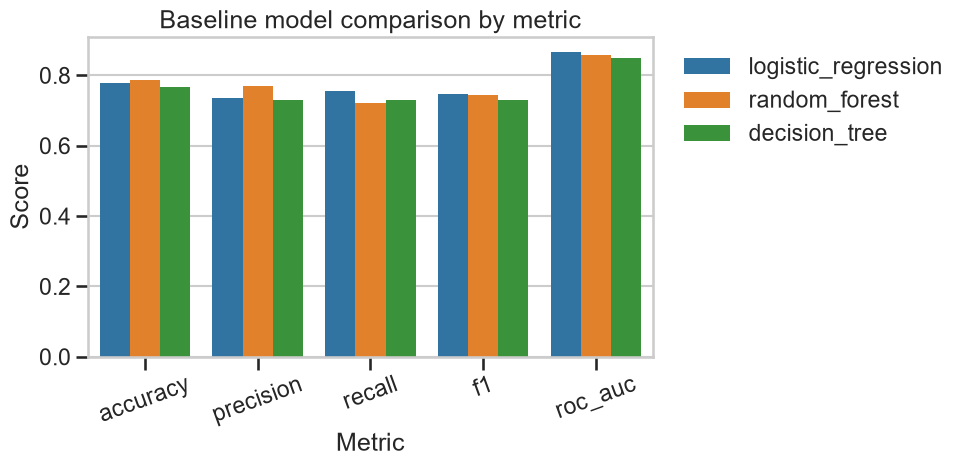

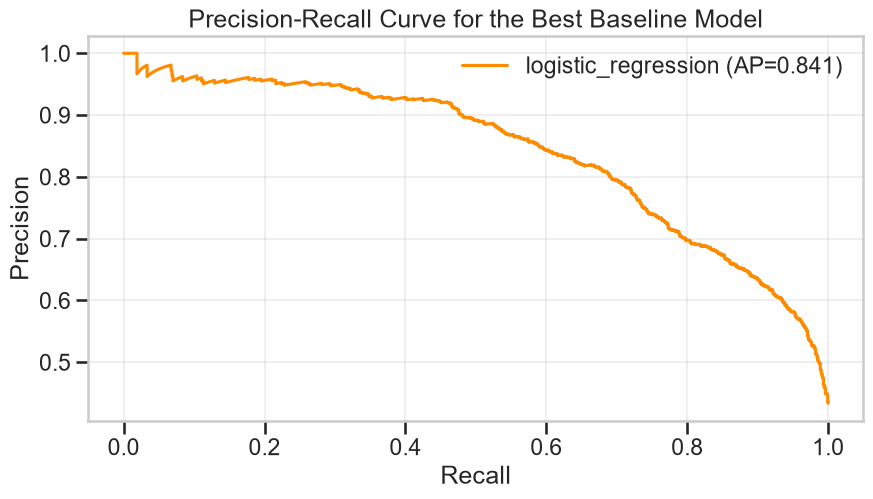

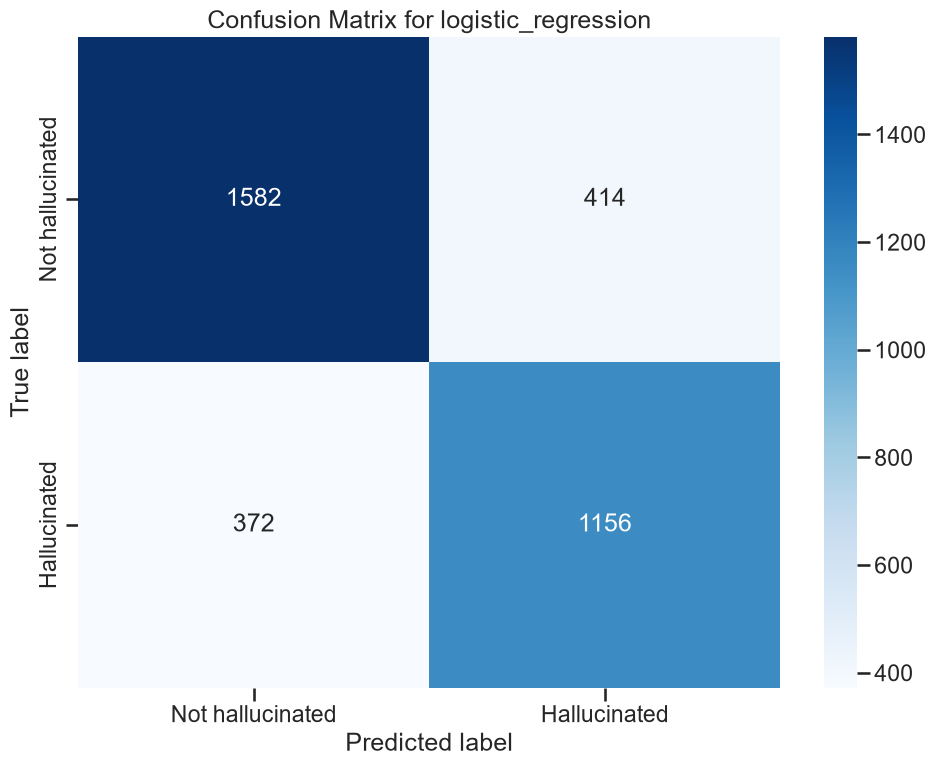

In [14]:
metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
plot_df = results_df.melt(id_vars='model', value_vars=metrics, var_name='metric', value_name='score')

plt.figure(figsize=(10, 5))
sns.barplot(data=plot_df, x='metric', y='score', hue='model')
plt.title('Baseline model comparison by metric')
plt.ylabel('Score')
plt.xlabel('Metric')
plt.xticks(rotation=20)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Precision-recall curve for the best model by F1.
best_name = results_df.iloc[0]['model']
best_model = trained_models[best_name]
y_prob_best = best_model.predict_proba(X_test)[:, 1]
precision, recall, _ = precision_recall_curve(y_test, y_prob_best)

plt.figure(figsize=(10, 5))
plt.plot(recall, precision, label=f'{best_name} (AP={average_precision_score(y_test, y_prob_best):.3f})', color='darkorange')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve for the Best Baseline Model')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# Heatmap of the confusion matrix for the best model.
cm = confusion_matrix(y_test, best_model.predict(X_test))
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Not hallucinated', 'Hallucinated'], yticklabels=['Not hallucinated', 'Hallucinated'])
plt.title(f'Confusion Matrix for {best_name}')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.tight_layout()
plt.show()

## 5. Select the strongest baseline

The final step is to decide which model should serve as the benchmark for future experiments. In many text-classification tasks, the best model is the one with the highest F1-score or the highest recall while keeping precision within an acceptable range. This decision must be justified clearly, because all later experiments will be compared against it.

The notebook therefore stores the selected benchmark and records the reasons for the choice so that the report can explain the model-selection logic in a reproducible way.

In [16]:
best_model_name = results_df.iloc[0]['model']
print(f'
Selected benchmark model: {best_model_name}')
print('Metric summary for the best model:')
print(results_df.head(1).to_string(index=False))

# Save a small summary for later tasks, next to features.csv in the project root.
output_path = feature_path.parent / 'baseline_model_results.csv'
results_df.to_csv(output_path, index=False)
print('
Saved baseline model comparison to: data/processed/baseline_model_results.csv')


Selected benchmark model: logistic_regression
Metric summary for the best model:
              model  accuracy  precision   recall       f1  roc_auc  average_precision
logistic_regression  0.776958   0.736306 0.756545 0.746288 0.867044           0.840727

Saved baseline model comparison to: data/processed/baseline_model_results.csv
